In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
observables1 = ['pt','b','dr','z','epair','w','reject','pt1','pt2','qlead','qsublead','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects','pt1s','pt2s','qleads','qsubleads','y1s','y2s','phi1s','phi2s']

In [3]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [4]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [5]:
def getRc(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    return (n_ss-n_os)/(n_ss+n_os)

In [6]:
def getRcs(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    return (n_ss-n_os)/(n_ss+n_os)

In [7]:
def getRcErr(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    n_unweighted = dataframe[dataframe.b==1].shape[0] + dataframe[dataframe.b==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [8]:
def getRcsErr(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    n_unweighted = dataframe[dataframe.bs==1].shape[0] + dataframe[dataframe.bs==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [9]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [10]:
def w_norm_per_xbin(h,x,y):
    w = np.empty([len(x)-1,len(y)-1])
    for i in range(0,len(x)-1):
        for j in range(0,len(y)-1):
            w[i][j] = h[i][j]/sum(h[i]) + 10**-50
    return w

In [11]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

In [12]:
df = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_chargedrc.root', "MatchedTree"),'bs!=-9 and b!=-9 and reject<=0 and rejects<=0')

In [13]:
distance1 = []
distance2 = []
for i in range(0,df.shape[0]):
    phi1small = min(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi1large = max(df.iloc[i]['phi1'], df.iloc[i]['phi1s'])
    phi2small = min(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    phi2large = max(df.iloc[i]['phi2'], df.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df.iloc[i]['phi1'], df.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df.iloc[i]['y1']-df.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df.iloc[i]['y2']-df.iloc[i]['y2s'])**2))
df['distance1'] = distance1
df['distance2'] = distance2

In [14]:
matching1 = []
matching2 = []

for i in range(0, df.shape[0]):
    if (df.iloc[i]['qlead'] == 3 and df.iloc[i]['qleads'] == -3 and df.iloc[i]['distance1'] < 0.02): # q unmatched, dr matched
        matching1.append(1)
    elif (df.iloc[i]['qlead'] == -3 and df.iloc[i]['qleads'] == 3 and df.iloc[i]['distance1'] < 0.02):
        matching1.append(-1)
    elif (df.iloc[i]['qlead'] == 3 and df.iloc[i]['qleads'] == -3 and df.iloc[i]['distance1'] > 0.02): # q unmatched, dr unmatch
        matching1.append(2)
    elif (df.iloc[i]['qlead'] == -3 and df.iloc[i]['qleads'] == 3 and df.iloc[i]['distance1'] > 0.02):
        matching1.append(-2)
    elif (df.iloc[i]['qlead'] == 3 and df.iloc[i]['qleads'] == 3 and df.iloc[i]['distance1'] > 0.02): # q matched, dr unmatched
        matching1.append(3)
    elif (df.iloc[i]['qlead'] == -3 and df.iloc[i]['qleads'] == -3 and df.iloc[i]['distance1'] > 0.02):
        matching1.append(-3)
    else:
        matching1.append(0)

    if (df.iloc[i]['qsublead'] == 3 and df.iloc[i]['qsubleads'] == -3 and df.iloc[i]['distance2'] < 0.02):
        matching2.append(1)
    elif (df.iloc[i]['qsublead'] == -3 and df.iloc[i]['qsubleads'] == 3 and df.iloc[i]['distance2'] < 0.02):
        matching2.append(-1)
    elif (df.iloc[i]['qsublead'] == 3 and df.iloc[i]['qsubleads'] == -3 and df.iloc[i]['distance2'] > 0.02):
        matching2.append(2)
    elif (df.iloc[i]['qsublead'] == -3 and df.iloc[i]['qsubleads'] == 3 and df.iloc[i]['distance2'] > 0.02):
        matching2.append(-2)
    elif (df.iloc[i]['qsublead'] == 3 and df.iloc[i]['qsubleads'] == 3 and df.iloc[i]['distance2'] > 0.02): 
        matching2.append(3)
    elif (df.iloc[i]['qsublead'] == -3 and df.iloc[i]['qsubleads'] == -3 and df.iloc[i]['distance2'] > 0.02):
        matching2.append(-3)
    else:
        matching2.append(0)
        
df['matching1'] = matching1
df['matching2'] = matching2

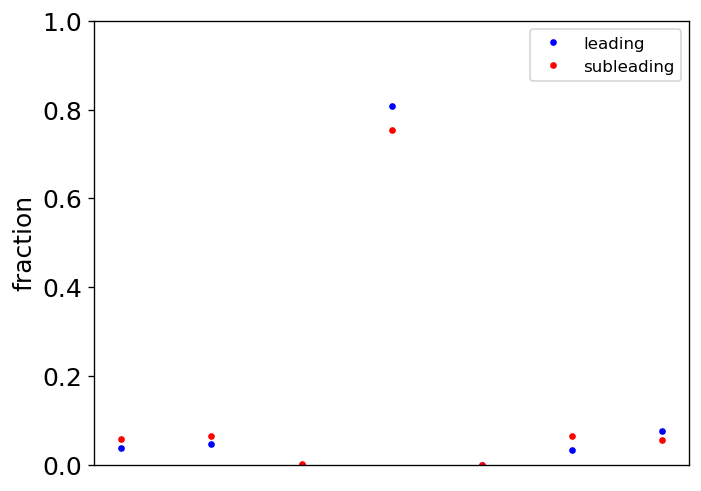

In [15]:
y1, yerr1, x = calc_hist(df[np.logical_and(df.pt1>2, df.pt1<2.1)]['matching1'], weights=df[np.logical_and(df.pt1>2, df.pt1<2.1)]['w'], density=True, bins=np.arange(-3.5,4.5))
y2, yerr2, x = calc_hist(df[np.logical_and(df.pt2>2, df.pt2<2.1)]['matching2'], weights=df[np.logical_and(df.pt2>2, df.pt2<2.1)]['w'], density=True, bins=np.arange(-3.5,4.5))
plt.plot(x[:-1], y1/sum(y1), 'b.', label='leading')
plt.plot(x[:-1], y2/sum(y2), 'r.', label='subleading')
plt.ylim(0,1)
plt.xticks([])
plt.ylabel('fraction')
plt.legend(fontsize=10)

In [16]:
dfpp = applyCut(df, 'qlead > 0 and qsublead > 0')
dfnn = applyCut(df, 'qlead < 0 and qsublead < 0')
dfpn = applyCut(df, 'qlead > 0 and qsublead < 0')
dfnp = applyCut(df, 'qlead < 0 and qsublead > 0')

In [17]:
sum(dfpp[np.logical_and(dfpp.matching1==0,dfpp.matching2==0)]['w'])/sum(dfpp['w'])

0.6682914059132344

In [18]:
sum(dfnn[np.logical_and(dfnn.matching1==0,dfnn.matching2==0)]['w'])/sum(dfnn['w'])

0.6795775549367935

In [19]:
sum(dfpn[np.logical_and(dfpn.matching1==0,dfpn.matching2==0)]['w'])/sum(dfpn['w'])

0.7026779614384985

In [20]:
sum(dfnp[np.logical_and(dfnp.matching1==0,dfnp.matching2==0)]['w'])/sum(dfnp['w'])

0.713483322846129

inverse of response matrix

In [21]:
h,x,y = np.histogram2d(df['bs'],df['b'], bins=([-1.,0,1.]), weights=df['w'], density=True)

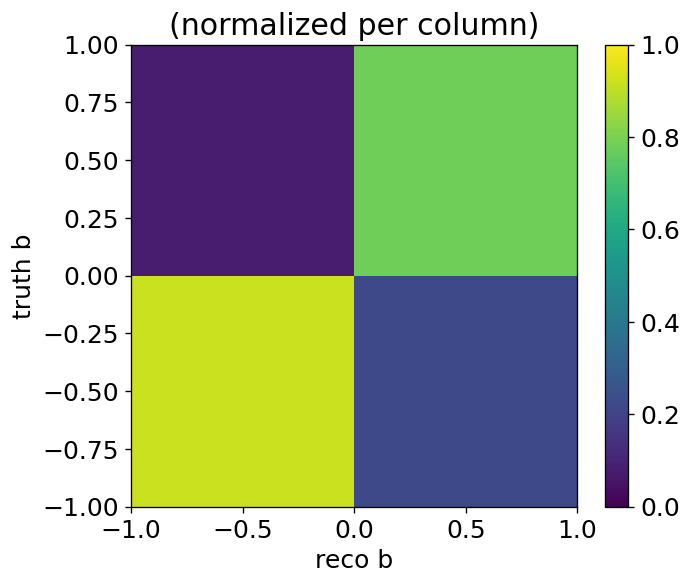

In [23]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[-1.,0,1.],[-1.,0,1.])
plt.pcolormesh([-1.,0,1.],[-1.,0,1.], np.transpose(w))
plt.xlabel('reco b')
plt.ylabel('truth b')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(-1.,1.)
plt.ylim(-1.,1.)
plt.clim(0,1)

If reco tracks have opposite sign, then it's less likely to be a fake pair, compared to if reco tracks have the same sign

In [24]:
w

array([[0.91797857, 0.08202143],
       [0.21940008, 0.78059992]])

In [25]:
h

array([[0.61812932, 0.05522989],
       [0.07166502, 0.25497578]])

response matrix

In [26]:
h,x,y = np.histogram2d(df['b'],df['bs'], bins=([-1.,0,1.]), weights=df['w'], density=True)

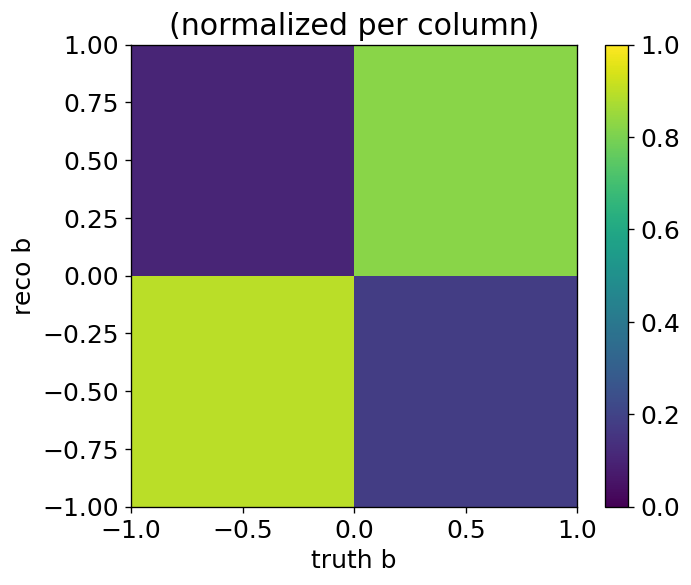

In [27]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[-1.,0,1.],[-1.,0,1.])
plt.pcolormesh([-1.,0,1.],[-1.,0,1.], np.transpose(w))
plt.ylabel('reco b')
plt.xlabel('truth b')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(-1.,1)
plt.ylim(-1.,1)
plt.clim(0,1)

In [28]:
w

array([[0.89610669, 0.10389331],
       [0.1780428 , 0.8219572 ]])

In [29]:
bins = 10.0**(np.arange(-2,-0.5,0.1))

In [30]:
bins = np.concatenate([np.arange(0, 0.32, 0.02), np.arange(0.4, 0.7, 0.1)])

In [31]:
bins

array([0.  , 0.02, 0.04, 0.06, 0.08, 0.1 , 0.12, 0.14, 0.16, 0.18, 0.2 ,
       0.22, 0.24, 0.26, 0.28, 0.3 , 0.4 , 0.5 , 0.6 ])

In [32]:
bincenter = (bins[:-1] + bins[1:])/2

(array([7.5830e+03, 3.2851e+04, 3.2490e+04, 1.6286e+04, 8.1430e+03,
        1.9220e+03, 2.6700e+02, 3.5000e+01, 5.0000e+00, 1.0000e+00]),
 array([ 5.00101975, 11.87145598, 18.7418922 , 25.61232843, 32.48276465,
        39.35320087, 46.2236371 , 53.09407332, 59.96450955, 66.83494577,
        73.70538199]),
 <BarContainer object of 10 artists>)

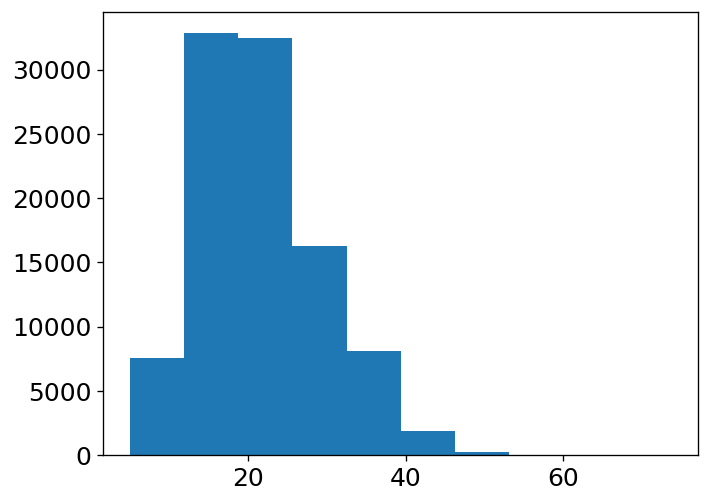

In [33]:
plt.hist(df['pt'])

(array([3.9887e+04, 3.0701e+04, 1.7540e+04, 7.6170e+03, 2.9330e+03,
        7.3300e+02, 1.4300e+02, 2.4000e+01, 4.0000e+00, 1.0000e+00]),
 array([10.00029999, 15.97876561, 21.95723123, 27.93569685, 33.91416247,
        39.89262809, 45.87109371, 51.84955933, 57.82802495, 63.80649057,
        69.78495619]),
 <BarContainer object of 10 artists>)

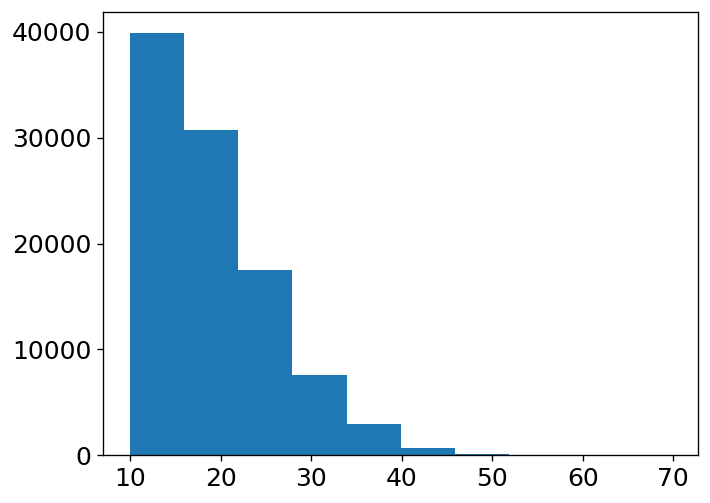

In [34]:
plt.hist(df['pts'])

(0.0, 0.6)

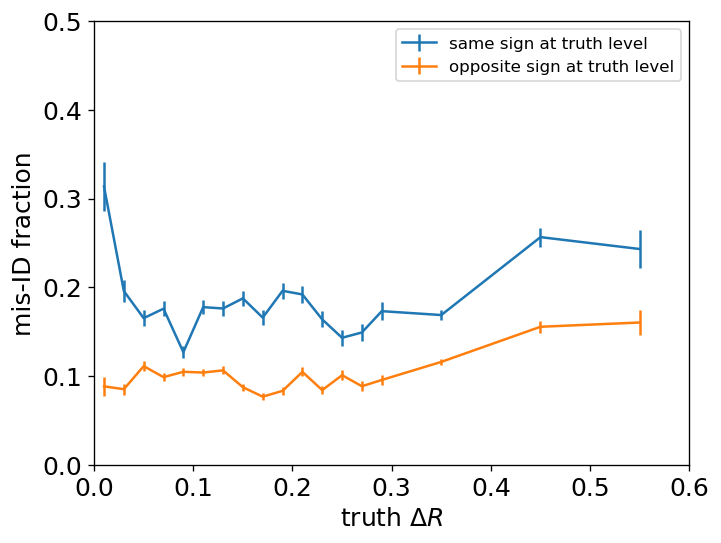

In [35]:
y_ss_misid = calc_hist(df[np.logical_and(df.bs==-1, df.b==1)]['dr'], weights=df[np.logical_and(df.bs==-1, df.b==1)]['w'],\
                       bins=bins)[0]
y_os_misid = calc_hist(df[np.logical_and(df.bs==1, df.b==-1)]['dr'], weights=df[np.logical_and(df.bs==1, df.b==-1)]['w'],\
                       bins=bins)[0]
y_ss = calc_hist(df[df.b==1]['dr'], weights=df[df.b==1]['w'], bins=bins)[0]
y_os = calc_hist(df[df.b==-1]['dr'], weights=df[df.b==-1]['w'], bins=bins)[0]
n_ss = calc_hist(df[df.b==1]['dr'], bins=bins)[0]
n_os = calc_hist(df[df.b==-1]['dr'], bins=bins)[0]
plt.errorbar(bincenter, y_ss_misid/y_ss, yerr=np.sqrt((y_ss_misid/y_ss)*(1-y_ss_misid/y_ss))/np.sqrt(n_ss),\
             label='same sign at truth level')
plt.errorbar(bincenter, y_os_misid/y_os, yerr=np.sqrt((y_os_misid/y_os)*(1-y_os_misid/y_os))/np.sqrt(n_os),\
             label='opposite sign at truth level')
plt.legend(fontsize=10)
plt.xlabel('truth $\Delta R$')
plt.ylabel('mis-ID fraction')
plt.ylim(0,0.5)
plt.xlim(0, 0.6)

In [36]:
df_test = applyCut(df, 'distance1 > 0.02 and distance2 > 0.02')

In [37]:
sum(df_test['w'])/sum(df['w'])

0.11071528197720477

(0.0, 0.6)

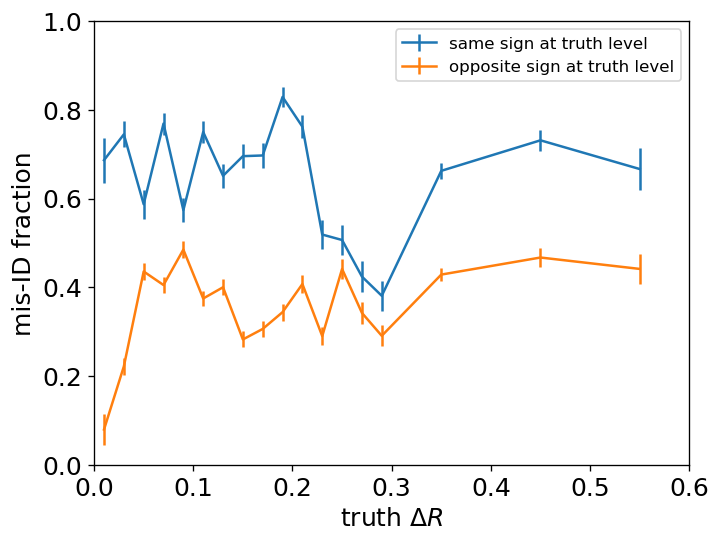

In [38]:
y_ss_misid = calc_hist(df_test[np.logical_and(df_test.bs==-1, df_test.b==1)]['dr'], weights=df_test[np.logical_and(df_test.bs==-1, df_test.b==1)]['w'],\
                       bins=bins)[0]
y_os_misid = calc_hist(df_test[np.logical_and(df_test.bs==1, df_test.b==-1)]['dr'], weights=df_test[np.logical_and(df_test.bs==1, df_test.b==-1)]['w'],\
                       bins=bins)[0]
y_ss = calc_hist(df_test[df_test.b==1]['dr'], weights=df_test[df_test.b==1]['w'], bins=bins)[0]
y_os = calc_hist(df_test[df_test.b==-1]['dr'], weights=df_test[df_test.b==-1]['w'], bins=bins)[0]
n_ss = calc_hist(df_test[df_test.b==1]['dr'], bins=bins)[0]
n_os = calc_hist(df_test[df_test.b==-1]['dr'], bins=bins)[0]
plt.errorbar(bincenter, y_ss_misid/y_ss, yerr=np.sqrt((y_ss_misid/y_ss)*(1-y_ss_misid/y_ss))/np.sqrt(n_ss),\
             label='same sign at truth level')
plt.errorbar(bincenter, y_os_misid/y_os, yerr=np.sqrt((y_os_misid/y_os)*(1-y_os_misid/y_os))/np.sqrt(n_os),\
             label='opposite sign at truth level')
plt.legend(fontsize=10)
plt.xlabel('truth $\Delta R$')
plt.ylabel('mis-ID fraction')
plt.ylim(0,1)
plt.xlim(0,0.6)

In [39]:
df_test = applyCut(df, '(distance1 > 0.02 and distance2 < 0.02) or (distance1 < 0.02 and distance2 > 0.02)')

In [40]:
sum(df_test['w'])/sum(df['w'])

0.1915578050078269

(0.0, 0.6)

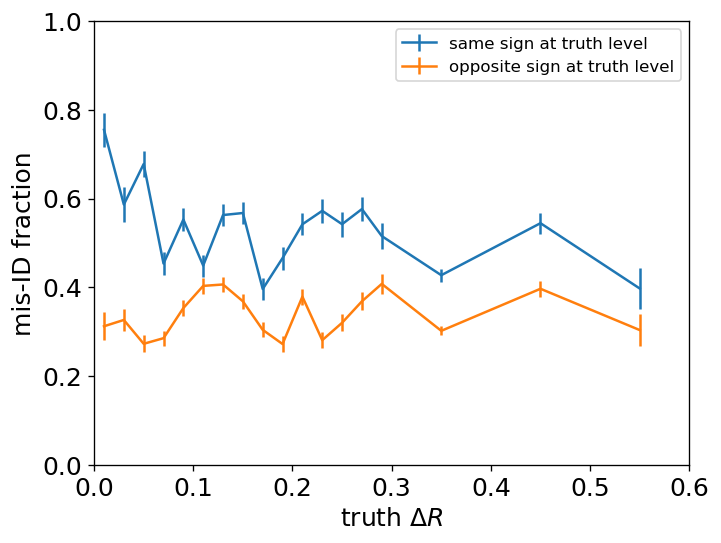

In [41]:
y_ss_misid = calc_hist(df_test[np.logical_and(df_test.bs==-1, df_test.b==1)]['dr'], weights=df_test[np.logical_and(df_test.bs==-1, df_test.b==1)]['w'],\
                       bins=bins)[0]
y_os_misid = calc_hist(df_test[np.logical_and(df_test.bs==1, df_test.b==-1)]['dr'], weights=df_test[np.logical_and(df_test.bs==1, df_test.b==-1)]['w'],\
                       bins=bins)[0]
y_ss = calc_hist(df_test[df_test.b==1]['dr'], weights=df_test[df_test.b==1]['w'], bins=bins)[0]
y_os = calc_hist(df_test[df_test.b==-1]['dr'], weights=df_test[df_test.b==-1]['w'], bins=bins)[0]
n_ss = calc_hist(df_test[df_test.b==1]['dr'], bins=bins)[0]
n_os = calc_hist(df_test[df_test.b==-1]['dr'], bins=bins)[0]
plt.errorbar(bincenter, y_ss_misid/y_ss, yerr=np.sqrt((y_ss_misid/y_ss)*(1-y_ss_misid/y_ss))/np.sqrt(n_ss),\
             label='same sign at truth level')
plt.errorbar(bincenter, y_os_misid/y_os, yerr=np.sqrt((y_os_misid/y_os)*(1-y_os_misid/y_os))/np.sqrt(n_os),\
             label='opposite sign at truth level')
plt.legend(fontsize=10)
plt.xlabel('truth $\Delta R$')
plt.ylabel('mis-ID fraction')
plt.ylim(0,1)
plt.xlim(0,0.6)

In [42]:
df_test = applyCut(df, 'distance1 < 0.02 and distance2 < 0.02')

In [45]:
df_test.shape[0]

65578

In [46]:
df.shape[0]

99583

In [43]:
sum(df_test['w'])/sum(df['w'])

0.6977269130149684

(0.0, 0.6)

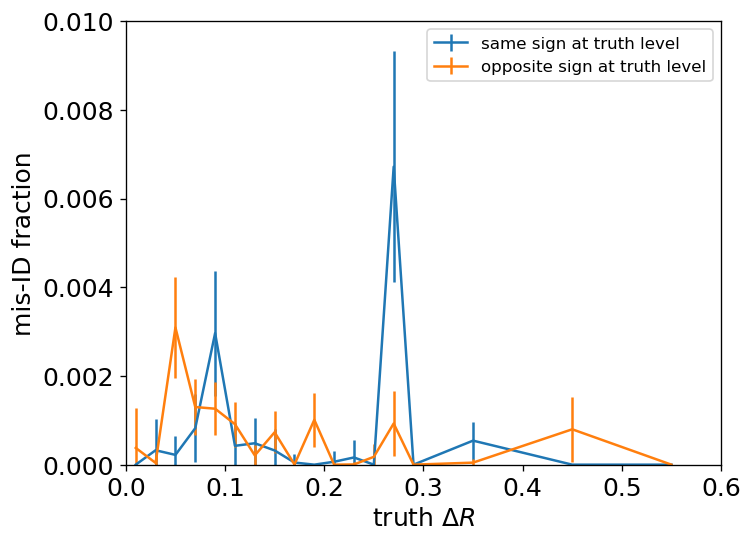

In [44]:
y_ss_misid = calc_hist(df_test[np.logical_and(df_test.bs==-1, df_test.b==1)]['dr'], weights=df_test[np.logical_and(df_test.bs==-1, df_test.b==1)]['w'],\
                       bins=bins)[0]
y_os_misid = calc_hist(df_test[np.logical_and(df_test.bs==1, df_test.b==-1)]['dr'], weights=df_test[np.logical_and(df_test.bs==1, df_test.b==-1)]['w'],\
                       bins=bins)[0]
y_ss = calc_hist(df_test[df_test.b==1]['dr'], weights=df_test[df_test.b==1]['w'], bins=bins)[0]
y_os = calc_hist(df_test[df_test.b==-1]['dr'], weights=df_test[df_test.b==-1]['w'], bins=bins)[0]
n_ss = calc_hist(df_test[df_test.b==1]['dr'], bins=bins)[0]
n_os = calc_hist(df_test[df_test.b==-1]['dr'], bins=bins)[0]
plt.errorbar(bincenter, y_ss_misid/y_ss, yerr=np.sqrt((y_ss_misid/y_ss)*(1-y_ss_misid/y_ss))/np.sqrt(n_ss),\
             label='same sign at truth level')
plt.errorbar(bincenter, y_os_misid/y_os, yerr=np.sqrt((y_os_misid/y_os)*(1-y_os_misid/y_os))/np.sqrt(n_os),\
             label='opposite sign at truth level')
plt.legend(fontsize=10)
plt.xlabel('truth $\Delta R$')
plt.ylabel('mis-ID fraction')
plt.ylim(0,0.01)
plt.xlim(0,0.6)